# REASSEMBLE: from one recording to one model sample

**A guided, read-only dataset walkthrough for a meeting.** REASSEMBLE records a robot picking, inserting, removing and placing objects during assembly and disassembly. Cameras show the manipulation; robot measurements describe its physical interaction. The local official description is `../datasets/REASSEMBLE/downloads/README.txt` (relative to this repository; the configured root is resolved below).

Our demonstrated task is **predicting whether a completed annotated action failed**. “Insert USB” is the **action context**; the stored `success` flag supplies the **outcome**. The binary model target is `failure = 1 − success`. Action text is not itself the target, and neither deep branch receives this text as an input.

We follow the preserved **Section 1 run `20260927T154732Z-section1`**, its own configuration and feature bank, and the inventory run `20260927T141645Z-inventory`. We explain its frozen visual backbone, statistical sensor baseline, and separate PatchTST sensor comparison. This is an earlier completed pipeline, **not a description of every later experiment**. Later Section 1B/2, additional improvements and boundary-aware visual runs remain separate; their arrays are not mixed into this walkthrough. Current research closure is documented in `artifacts/reassemble/reports/ADDITIONAL_IMPROVEMENTS_STATUS.md`.

### Meeting tour (about 12 minutes)

| Stop | What to ask |
|---|---|
| [1. Dataset overview](#overview) | What exists, and which population do we use? |
| [2. A recording and its annotations](#recording) | What is physically inside one file? |
| [3. One sample’s real images and clip](#images) | Which frames belong to this action? |
| [4. The same sample’s sensors](#sensors) | What did the robot measure at those times? |
| [5. Shape ledger](#shapes) | What numbers reach each branch? |
| [6. Code trace](#trace) | Where does each operation happen? |

Open the **executed HTML** for the meeting: plots and clips are embedded and no kernel or internet connection is needed. Source cells are visible in the notebook; the HTML hides them for readability. Browser playback is a separate check from successful media decoding.

### A few words before the first plot

A **recording** is a complete trial stored in one HDF5 file. A **segment** is an annotated start-to-end interval within that trial. An **annotation** is metadata supplied with the data, such as boundaries, a sentence and success flag. A **label** is the outcome used for learning. A **modality** is a kind of observation, such as video or force.

A **frame** is one image in a video. A **channel** is one measured component, for example one of three force components. A **feature** is a numerical description derived from observations. An **array** (or, in a model library, a **tensor**) is a block of numbers; its **shape** gives the number of entries along each dimension. A **batch** is several examples processed together.

**One recording → many annotated intervals → one eligible interval is one model sample → several alternative numerical representations of that same sample.** Sixteen frames from an interval are not sixteen independent action labels. A batch of frames in image preprocessing is also different from a training batch of action samples.

This notebook does not train, score predictions, regenerate inventories or feature banks, or download anything.

### Parameters — the only cell you normally edit

Keep the run fixed to reproduce this walkthrough. Change `ACTION` or set a composite `(recording_id, segment_id)` under `MANUAL`. IDs are strings: segment `"2"` alone is not unique across recordings. Manual examples must belong to this run’s cohort and have the requested outcome. Environment variable `REASSEMBLE_DATA_ROOT` or the runner’s `--data-root` overrides the raw-data location; it never changes the selected feature run.

In [1]:
from pathlib import Path
import os

CONFIG_PATH = "runs/reassemble/20260927T154732Z-section1/config.json"
ACTION = "insert"
MANUAL = {"success": None, "failure": None}  # e.g. ("2025-01-11-14-14-43", "2")
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "REPO_MAP.md").exists() and (p / "src/reassemble").exists())

In [2]:
import sys, json, inspect, hashlib
from datetime import datetime, timezone
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image, Video

sys.dont_write_bytecode = True
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "tutorials/EDA"))
from reassemble_support import (identity, digest, reference, load_sample,
                                 contact_sheet, sensor_figure, export_clip)

# Running this cell interactively also allocates a NEW output directory.
if "WALKTHROUGH_OUTPUT" in os.environ:
    OUT = Path(os.environ["WALKTHROUGH_OUTPUT"])
else:
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    OUT = ROOT / "runs/reassemble" / (stamp + "-dataset-walkthrough")
    OUT.mkdir(parents=True, exist_ok=False)
    (OUT / ".gitignore").write_text("*\n")
for name in ("figures", "media", "tables", "reports", "manifests", "config", "runtime"):
    (OUT / name).mkdir(exist_ok=True)
os.environ["MPLCONFIGDIR"] = str(OUT / "runtime/matplotlib")
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["TRANSFORMERS_OFFLINE"] = "1"
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import cv2, h5py
cv2.setNumThreads(1)
from reassemble.alignment import action_from_text, interval_indices, resample_progress
from reassemble.inventory import scalar
from reassemble.section1_features import cohort, statistics, extract
from reassemble.section1_models import load_features, evaluate_model, Standardizer, VisualHead, SensorHead

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 100)
config = json.loads((ROOT / CONFIG_PATH).read_text())
DATA = Path(os.environ.get("REASSEMBLE_DATA_ROOT", str(ROOT / config["data_root"]))).resolve()
AUDIT, RUN = ROOT / config["audit_run"], ROOT / config["run_dir"]
inputs, warnings, checks = {}, [], {}
def track(path, checksum=False):
    inputs[os.path.relpath(path, ROOT)] = identity(path, ROOT, checksum)
def table(frame):
    display(frame.style.hide(axis="index"))
def show_figure(fig, filename):
    path = OUT / "figures" / filename
    fig.savefig(path, dpi=120, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(path)))
for p in [ROOT/CONFIG_PATH, ROOT/"configs/reassemble/section1.json",
          ROOT/"configs/reassemble/audit.json", ROOT/"docs/reassemble/AUDIT_METHODS.md",
          RUN/"pretrained_model.json", AUDIT/"reports_v2/modality_selection.json",
          AUDIT/"reports_v2/known_issues.json"]:
    track(p, True)
config_snapshot = {"source": CONFIG_PATH, "pipeline": config, "action": ACTION, "manual": MANUAL,
                   "resolved_data_root_relative_to_repository": os.path.relpath(DATA, ROOT),
                   "output_relative_to_repository": os.path.relpath(OUT, ROOT),
                   "duplicate_policy": "preserve existing cohort; no deduplication",
                   "sample_identity": ["recording_id", "segment_id"]}
(OUT/"config/resolved_config.json").write_text(json.dumps(config_snapshot, indent=2))
path_rows = [("Configured data root", config["data_root"], (ROOT/config["data_root"]).exists()),
             ("Resolved data root (override allowed)", os.path.relpath(DATA, ROOT), DATA.exists()),
             ("Raw recording folder", os.path.relpath(DATA/"raw/data", ROOT), (DATA/"raw/data").exists()),
             ("Selected feature bank", str(Path(config["run_dir"])/"features"), (RUN/"features").exists())]
table(pd.DataFrame(path_rows, columns=["role", "path", "confirmed exists now"]))

/home/student/Master_Thesis_WS/pi-multimodal-ad/ma_thesis_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


role,path,confirmed exists now
Configured data root,../datasets/REASSEMBLE,True
Resolved data root (override allowed),../datasets/REASSEMBLE,True
Raw recording folder,../datasets/REASSEMBLE/raw/data,True
Selected feature bank,runs/reassemble/20260927T154732Z-section1/features,True


### Navigation: data → readers → features → modelling

| Boundary | Repository location | What crosses it |
|---|---|---|
| Physical data | configured root `/raw/data/<recording>.h5`; optional `/raw/poses/<recording>_poses.json` | Encoded media, numeric streams, timestamps, annotations |
| Reader and inventory | `src/reassemble/inventory.py:scalar`, `audit_recording`; `src/reassemble/media.py:inspect_video` | Annotation rows; metadata; keyed encoded-video cache |
| Alignment | `src/reassemble/alignment.py:interval_indices`, `resample_progress` | In-interval frames; common sensor progress grid |
| Feature extraction | `src/reassemble/section1_features.py:cohort`, `extract`, `statistics` | Frame indices, sensor sequence, channel statistics, visual vector |
| Saved-feature boundary | selected run’s `features/<recording>.npz` + `.json` | `row_index`, `sensor`, `statistics`, `visual`, `frame_indices` |
| Model loading | `src/reassemble/section1_models.py:load_features`, `evaluate_model` | Arrays ordered by cohort row; separate branch inputs |

The scripts `scripts/reassemble/01_inventory.py`, `03_section1_features.py`, and `04_section1_train.py` are entry points. We do **not** call those jobs. Detailed line references and short excerpts appear in the final trace.

<a id="overview"></a>
## 1. What exists, and what do we actually use?

The following totals are recomputed from **existing saved tables** and a cheap filename listing. They are not a fresh audit of all recordings. Raw-file presence, inventoried annotations and model-cohort membership are three different claims. Files are listed without decoding their contents.

In [3]:
recordings = pd.read_parquet(AUDIT / "recordings.parquet")
segments = pd.read_parquet(AUDIT / "segments.parquet")
all_rows = pd.read_parquet(AUDIT / "tables_v2/cohort.parquet")
read_config = {**config, "audit_run": str(AUDIT)}
selected = cohort(read_config)  # existing filter; includes historical cohort assertions
saved_cohort = pd.read_parquet(RUN / "cohort.parquet")
cols = ["recording_id", "segment_id", "start", "end", "action", "failure"]
pd.testing.assert_frame_equal(selected[cols], saved_cohort[cols], check_dtype=False)
assert not selected.duplicated(["recording_id", "segment_id"]).any()
assert selected.success.notna().all() and selected.failure.isin([0, 1]).all()
assert np.array_equal(selected.failure, (~selected.success).astype(int))
for p in [AUDIT/"recordings.parquet", AUDIT/"segments.parquet", AUDIT/"tables_v2/cohort.parquet", RUN/"cohort.parquet"]:
    track(p, True)
raw_files = sorted((DATA / "raw/data").glob("*.h5"))
raw_before = {p.name: [p.stat().st_size, p.stat().st_mtime_ns] for p in raw_files}
primary = all_rows[all_rows.primary_task]
summary = pd.DataFrame([
    ["Locally present .h5 files (filename listing only)", len(raw_files), None, None, None],
    ["Saved inventory: all annotations", recordings.recording_id.nunique(), len(segments), int((segments.failure==0).sum()), int((segments.failure==1).sum())],
    ["Saved audit: recognized primary actions", primary.recording_id.nunique(), len(primary), int((primary.failure==0).sum()), int((primary.failure==1).sum())],
    ["Selected Section 1 cohort: primary_task AND dual_complete", selected.recording_id.nunique(), len(selected), int((selected.failure==0).sum()), int((selected.failure==1).sum())]],
    columns=["population", "recordings", "segments", "success", "failure"])
table(summary)
summary.to_csv(OUT/"tables/populations.csv", index=False)
checks["saved_cohort_identity_and_order_match"] = True
print("Inventoried recording filenames missing locally:", len(set(recordings.filename)-{p.name for p in raw_files}))

population,recordings,segments,success,failure
Locally present .h5 files (filename listing only),149,nan,nan,nan
Saved inventory: all annotations,149,4863.000000,4346.000000,517.000000
Saved audit: recognized primary actions,149,4551.000000,4035.000000,516.000000
Selected Section 1 cohort: primary_task AND dual_complete,148,4530.000000,4021.000000,509.000000


Inventoried recording filenames missing locally: 0


**How an annotation enters this cohort.** `alignment.action_from_text` recognizes leading forms of pick, insert, remove and place; other text (including idle) remains in the inventory. `audit_report.main` defines `primary_task` as a recognized action with a finite, positive interval. `dual_complete` additionally requires usable hand-camera video and all five sensor streams.

The audit requires at least 90% timestamp coverage, at least 90% finite resampled sensor coverage, no wholly missing sensor channel and at least two native measurements. Video requires matching frame/timestamp counts, coverage ≥90% and all 16 sampled frames decoding. Documented final-action force/torque or gripper defects conservatively exclude those streams; raw annotations are retained. Camera choice uses availability and a hand-proximity tie-break, not model performance. Definitions: `inventory.audit_recording`, `media.inspect_video`, `audit_report.main`; methodology: `docs/reassemble/AUDIT_METHODS.md`.

**Time units:** the audited data use absolute Unix timestamps in **seconds** (`docs/reassemble/AUDIT_METHODS.md`, actual-schema corrections). Duration is `end − start`, so it is also seconds. Later plots subtract segment start for legibility; they do not change the clock scale.

saved mask / reason,segments
All annotations,4863
Excluded: not a recognized valid primary action,312
Primary actions excluded by modality/known-issue masks,21
Primary actions with unusable selected video (overlapping reason),9
Primary actions with unusable sensors (overlapping reason),13


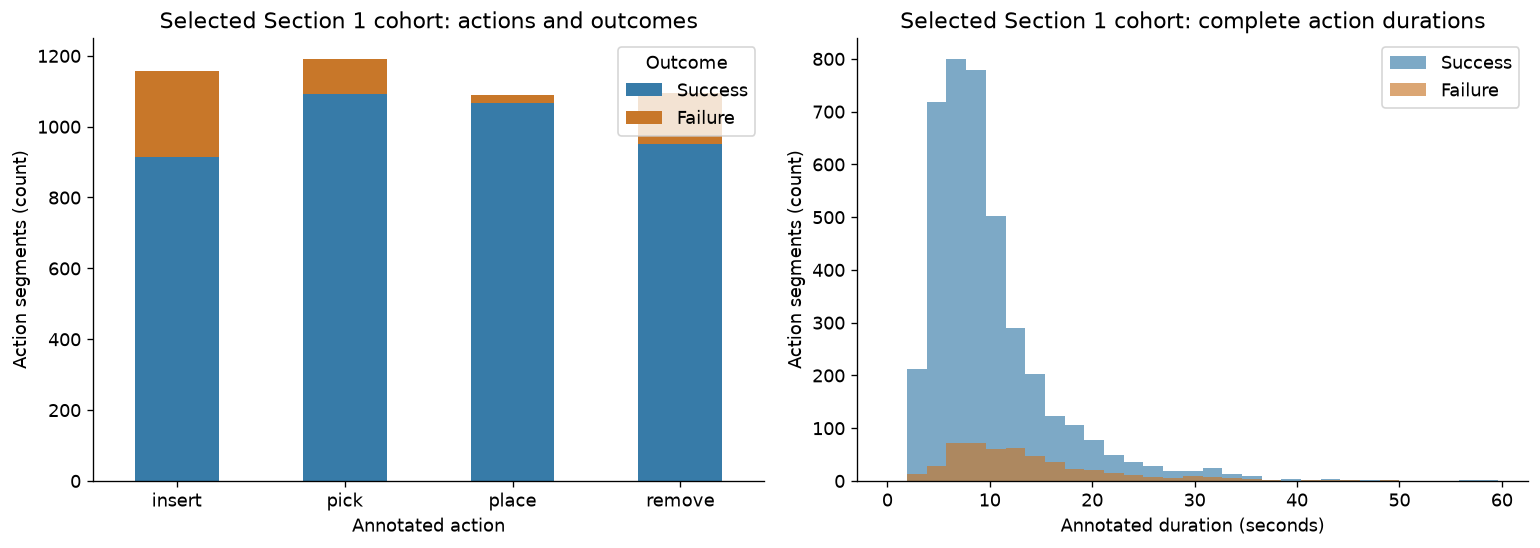

action,Success,Failure
insert,913,243
pick,1092,98
place,1066,22
remove,950,146


In [4]:
exclusions = pd.DataFrame([
    ["All annotations", len(all_rows)],
    ["Excluded: not a recognized valid primary action", int((~all_rows.primary_task).sum())],
    ["Primary actions excluded by modality/known-issue masks", int((all_rows.primary_task & ~all_rows.dual_complete).sum())],
    ["Primary actions with unusable selected video (overlapping reason)", int((primary.visual_usable==False).sum())],
    ["Primary actions with unusable sensors (overlapping reason)", int((primary.sensor_usable==False).sum())]], columns=["saved mask / reason", "segments"])
table(exclusions)
counts = pd.crosstab(selected.action, selected.failure).reindex(columns=[0,1], fill_value=0).rename(columns={0:"Success",1:"Failure"})
fig, axes = plt.subplots(1, 2, figsize=(13, 4.7))
counts.plot.bar(stacked=True, ax=axes[0], color=["#377ba8", "#c87729"], rot=0)
axes[0].get_legend().set_title("Outcome")
axes[0].set(title="Selected Section 1 cohort: actions and outcomes", xlabel="Annotated action", ylabel="Action segments (count)")
for value, name, color in [(0,"Success","#377ba8"),(1,"Failure","#c87729")]:
    axes[1].hist(selected.loc[selected.failure==value, "duration"], bins=np.linspace(0,selected.duration.max(),32), alpha=.65, label=name, color=color)
axes[1].set(title="Selected Section 1 cohort: complete action durations", xlabel="Annotated duration (seconds)", ylabel="Action segments (count)")
axes[1].legend()
fig.tight_layout()
show_figure(fig, "overview.png")
table(counts.reset_index())

**What you are seeing:** action counts split by outcome and a duration histogram for the selected cohort only. The exclusion table distinguishes sequential exclusions from overlapping availability reasons.

**Why it matters:** a file can contain many actions, and the selected population has many more successes than failures. These figures describe the input population; they do not establish model quality or show what an individual failure looks like.

<a id="recording"></a>
## 2. Select two real examples and open one recording

**Deterministic rule:** within the fixed action `ACTION`, compute the duration median separately for success and failure in the selected cohort. Among rows with a local raw file, encoded hand-video cache and saved feature block, select the smallest absolute distance to that class median; break ties lexicographically by recording ID then segment ID. No predictions are consulted. If the action has no eligible class, that example is visibly unavailable. A manual composite ID overrides this rule and is reported.

These are **illustrations, not representative performance evidence**. The same action category may concern different objects, scenes or operators. An annotated failure need not be visually obvious.

In [5]:
record_index = recordings.set_index("recording_id")
availability = {}
for rid, rec in record_index.iterrows():
    availability[rid] = ((DATA/"raw/data"/rec.filename).exists()
                         and (DATA/"cache/encoded_media"/rec.sha256/"hand.mp4").exists()
                         and (RUN/"features"/(rid+".npz")).exists()
                         and (RUN/"features"/(rid+".json")).exists())
examples, selection_details = [], []
for label, target in [("success", 0), ("failure", 1)]:
    group = selected[(selected.action == ACTION) & (selected.failure == target)]
    median = group.duration.median()
    eligible = group[group.recording_id.map(availability)].copy()
    if MANUAL[label] is not None:
        rid, sid = map(str, MANUAL[label])
        eligible = selected[(selected.recording_id==rid) & (selected.segment_id==sid)]
        assert len(eligible)==1 and int(eligible.iloc[0].failure)==target
        assert availability[rid], "Manual example assets unavailable"
        row = eligible.iloc[0]
        rule = "manual composite-ID override"
    elif len(eligible):
        eligible["distance"] = (eligible.duration-median).abs()
        row = eligible.sort_values(["distance", "recording_id", "segment_id"]).iloc[0]
        rule = "nearest action/outcome median; recording_id then segment_id tie-break"
    else:
        warnings.append(f"UNAVAILABLE: no local {ACTION}/{label} example")
        display(Markdown(f"> **UNAVAILABLE:** no local {ACTION}/{label} example."))
        continue
    sample = load_sample(row, record_index.loc[row.recording_id], config, ROOT, DATA)
    examples.append(sample)
    for p, hashed in [(sample["raw"],False),(sample["bank"],True),(sample["meta_path"],True),(sample["video"],False)]:
        track(p, hashed)
    selection_details.append({"recording_id": row.recording_id, "segment_id": row.segment_id,
        "cohort_row_index": int(row.name), "feature_block_slot": sample["slot"],
        "outcome": label, "action": row.action, "annotation": row.text,
        "original_success": bool(sample["annotation"]["success"]), "model_failure_target": int(row.failure),
        "start_unix_seconds": float(row.start), "end_unix_seconds": float(row.end),
        "duration_seconds": float(row.duration), "class_median_seconds": float(median),
        "eligible_rows": len(group[group.recording_id.map(availability)]), "class_rows": len(group),
        "selection_rule": rule, "raw": os.path.relpath(sample["raw"],ROOT),
        "saved_features": os.path.relpath(sample["bank"],ROOT)})
for card in selection_details:
    display(Markdown(f"### {card['outcome'].title()}: `{card['recording_id']} / {card['segment_id']}`"))
    table(pd.DataFrame(card.items(), columns=["field", "value"]))
(OUT/"tables/selected_samples.json").write_text(json.dumps(selection_details, indent=2))
main = examples[0] if examples else None
checks["sample_raw_annotations_feature_rows_and_timestamps"] = bool(examples)
checks["single_sample_sensor_and_statistics_exact_saved_parity"] = bool(examples)

### Success: `2025-01-11-14-14-43 / 2`

field,value
recording_id,2025-01-11-14-14-43
segment_id,2
cohort_row_index,2106
feature_block_slot,1
outcome,success
action,insert
annotation,Insert USB.
original_success,True
model_failure_target,0
start_unix_seconds,1736601296.706378


### Failure: `2025-01-13-16-45-31 / 21`

field,value
recording_id,2025-01-13-16-45-31
segment_id,21
cohort_row_index,3326
feature_block_slot,20
outcome,failure
action,insert
annotation,Insert square peg 1.
original_success,False
model_failure_target,1
start_unix_seconds,1736783322.982649


In [6]:
if main:
    display(Markdown("### Physical structure: main recording"))
    display(Markdown(f"File: `{os.path.relpath(main['raw'],ROOT)}` — HDF5, opened with `h5py.File(..., 'r')`, as in `inventory.audit_recording`. Only dataset shapes/dtypes are inspected below; media payloads and events are not read for this table."))
    shallow = pd.DataFrame(main["schema"])
    table(shallow[~shallow.path.str.startswith("/timestamps/")])
    display(Markdown("Timestamp datasets (separate clock array per stream):"))
    table(shallow[shallow.path.str.startswith("/timestamps/")])
    display(Markdown("Actual annotation values read with the existing `inventory.scalar` reader:"))
    table(pd.DataFrame([main["annotation"]]))
    same_record = segments[segments.recording_id == main["row"].recording_id]
    display(Markdown("First five inventory annotation rows from this same recording:"))
    table(same_record[["segment_id","start","end","duration","text","success","failure"]].head())
    pose = DATA/"raw/poses"/(main["row"].recording_id+"_poses.json")
    print("Associated pose file:", os.path.relpath(pose, ROOT), "exists:", pose.exists())
    if pose.exists():
        track(pose, True)
        print("Pose metadata keys:", list(json.loads(pose.read_text())))

### Physical structure: main recording

File: `../datasets/REASSEMBLE/raw/data/2025-01-11-14-14-43.h5` — HDF5, opened with `h5py.File(..., 'r')`, as in `inventory.audit_recording`. Only dataset shapes/dtypes are inspected below; media payloads and events are not read for this table.

path,shape,dtype
/capture_node-camera-image,(),|V5706361
/events,"(51941872, 3)",int64
/hama1,(),|V18187794
/hama1_audio,"(5228712,)",int64
/hama2,(),|V16854574
/hama2_audio,"(5187168,)",int64
/hand,(),|V18942173
/hand_audio,"(3333456,)",int64
/robot_state,group,12 children
/segments_info,group,26 children


Timestamp datasets (separate clock array per stream):

path,shape,dtype
/timestamps/capture_node-camera-image,"(2038,)",float64
/timestamps/compensated_base_force,"(301112,)",float64
/timestamps/compensated_base_torque,"(301112,)",float64
/timestamps/events,"(51941872,)",float64
/timestamps/gripper_efforts,"(330409,)",float64
/timestamps/gripper_positions,"(330409,)",float64
/timestamps/gripper_velocities,"(330409,)",float64
/timestamps/hama1,"(10210,)",float64
/timestamps/hama2,"(10209,)",float64
/timestamps/hand,"(9466,)",float64


Actual annotation values read with the existing `inventory.scalar` reader:

start,end,success,text,index
1736601296.706378,1736601311.573055,True,Insert USB.,2


First five inventory annotation rows from this same recording:

segment_id,start,end,duration,text,success,failure
0,1736601283.889604,1736601286.206282,2.316678,No action.,True,0
1,1736601286.225935,1736601296.689673,10.463738,Pick USB.,True,0
2,1736601296.706378,1736601311.573055,14.866677,Insert USB.,True,0
3,1736601311.589652,1736601321.406319,9.816667,Pick Ethernet.,True,0
4,1736601321.422958,1736601338.156388,16.733430,Insert Ethernet.,True,0


Associated pose file: ../datasets/REASSEMBLE/raw/poses/2025-01-11-14-14-43_poses.json exists: True
Pose metadata keys: ['Hama1', 'Hama2', 'DAVIS346', 'NIST_Board1']


**Read the container like a folder.** `robot_state` and `timestamps` are HDF5 groups. Their children are numeric arrays of differing lengths because streams sample at different rates. `segments_info/<segment_id>` holds start/end, success, text and sometimes nested low-level skill annotations; the high-level interval is the sample here.

The camera entries are **encoded MP4 byte blobs**, not `(frames, height, width, colour)` arrays. In these recordings, a scalar shape `()` with a large `|V…` dtype means one opaque byte payload. The existing reader exports these to a recording-hash-keyed cache. We reuse that cache read-only, check its byte length against the HDF5 payload and verify decoded frame count against camera timestamps. This is metadata/cache-lineage verification, not a newly computed raw-file hash. The shape of an image is measured **after decoding** below.

The official local README has schematic inconsistencies (including a seven-component measured-torque entry described as x/y/z). Actual loaded shapes take precedence. Sensor unit attributes are absent in the selected arrays; this notebook uses the verified channel names and labels physical units **unknown** rather than inferring SI units.

In [7]:
if main:
    keys = {item["path"].split("/")[1] for item in main["schema"]}
    schema_paths = {item["path"] for item in main["schema"]}
    rows = []
    for stream, description, used in [
        ("hand", "hand/wrist RGB camera", "Yes: frozen visual features"),
        ("hama1", "external RGB camera view", "No"),
        ("hama2", "external RGB camera view", "No"),
        ("capture_node-camera-image", "event-camera image stream", "No"),
        ("events", "event-camera x/y/polarity observations", "No"),
        ("hama1_audio", "microphone encoded audio", "No: alignment unverified"),
        ("hama2_audio", "microphone encoded audio", "No: alignment unverified"),
        ("hand_audio", "hand microphone encoded audio", "No: alignment unverified")]:
        rows.append([stream, description, stream in keys, used, "Main HDF5 keys; section1_features.extract; saved audio audit"])
    descriptions = {"measured_force":"3 force components", "measured_torque":"3 torque components",
                    "gripper_positions":"2 gripper components", "joint_efforts":"7 joint effort components",
                    "joint_velocities":"7 joint velocity components"}
    for stream in config["sensor"]["channels"]:
        rows.append([stream, descriptions[stream], "/robot_state/"+stream in schema_paths,
                     "Yes: statistics and separate PatchTST branch", "HDF5 arrays; feature metadata channel_names"])
    rows.append(["Other robot_state streams", "pose, positions, velocity, compensated force/torque, etc.", True,
                 "No", "Main HDF5 schema above vs extractor's five-stream list"])
    table(pd.DataFrame(rows, columns=["stream", "what it measures/shows", "present locally in main recording", "used by demonstrated pipeline?", "evidence"]))
    display(Markdown("**Presence is not alignment or model use.** Audio byte streams exist, but the saved audit found no verified annotation-to-audio clock mapping. No audio waveform is presented as synchronized to this segment. See `artifacts/reassemble/reports/AUDIO_FEASIBILITY_HANDOFF.md`."))

stream,what it measures/shows,present locally in main recording,used by demonstrated pipeline?,evidence
hand,hand/wrist RGB camera,True,Yes: frozen visual features,Main HDF5 keys; section1_features.extract; saved audio audit
hama1,external RGB camera view,True,No,Main HDF5 keys; section1_features.extract; saved audio audit
hama2,external RGB camera view,True,No,Main HDF5 keys; section1_features.extract; saved audio audit
capture_node-camera-image,event-camera image stream,True,No,Main HDF5 keys; section1_features.extract; saved audio audit
events,event-camera x/y/polarity observations,True,No,Main HDF5 keys; section1_features.extract; saved audio audit
hama1_audio,microphone encoded audio,True,No: alignment unverified,Main HDF5 keys; section1_features.extract; saved audio audit
hama2_audio,microphone encoded audio,True,No: alignment unverified,Main HDF5 keys; section1_features.extract; saved audio audit
hand_audio,hand microphone encoded audio,True,No: alignment unverified,Main HDF5 keys; section1_features.extract; saved audio audit
measured_force,3 force components,True,Yes: statistics and separate PatchTST branch,HDF5 arrays; feature metadata channel_names
measured_torque,3 torque components,True,Yes: statistics and separate PatchTST branch,HDF5 arrays; feature metadata channel_names


**Presence is not alignment or model use.** Audio byte streams exist, but the saved audit found no verified annotation-to-audio clock mapping. No audio waveform is presented as synchronized to this segment. See `artifacts/reassemble/reports/AUDIO_FEASIBILITY_HANDOFF.md`.

<a id="images"></a>
## 3. What does one action sample look like?

The main contact sheet uses **every retained `frame_indices` entry in this sample’s saved feature block**. Indices are zero-based positions in the complete recording’s hand-camera video. Each caption shows the actual timestamp minus the annotated start, in seconds. The accompanying table retains absolute timestamps.

We also reconstruct the present extractor’s evenly spaced **index** selection and compare it exactly with the retained indices. Equality is checked; this is not a claim that every historical implementation detail was rerun. Uneven camera timing means evenly spaced indices need not be perfectly evenly spaced in time.

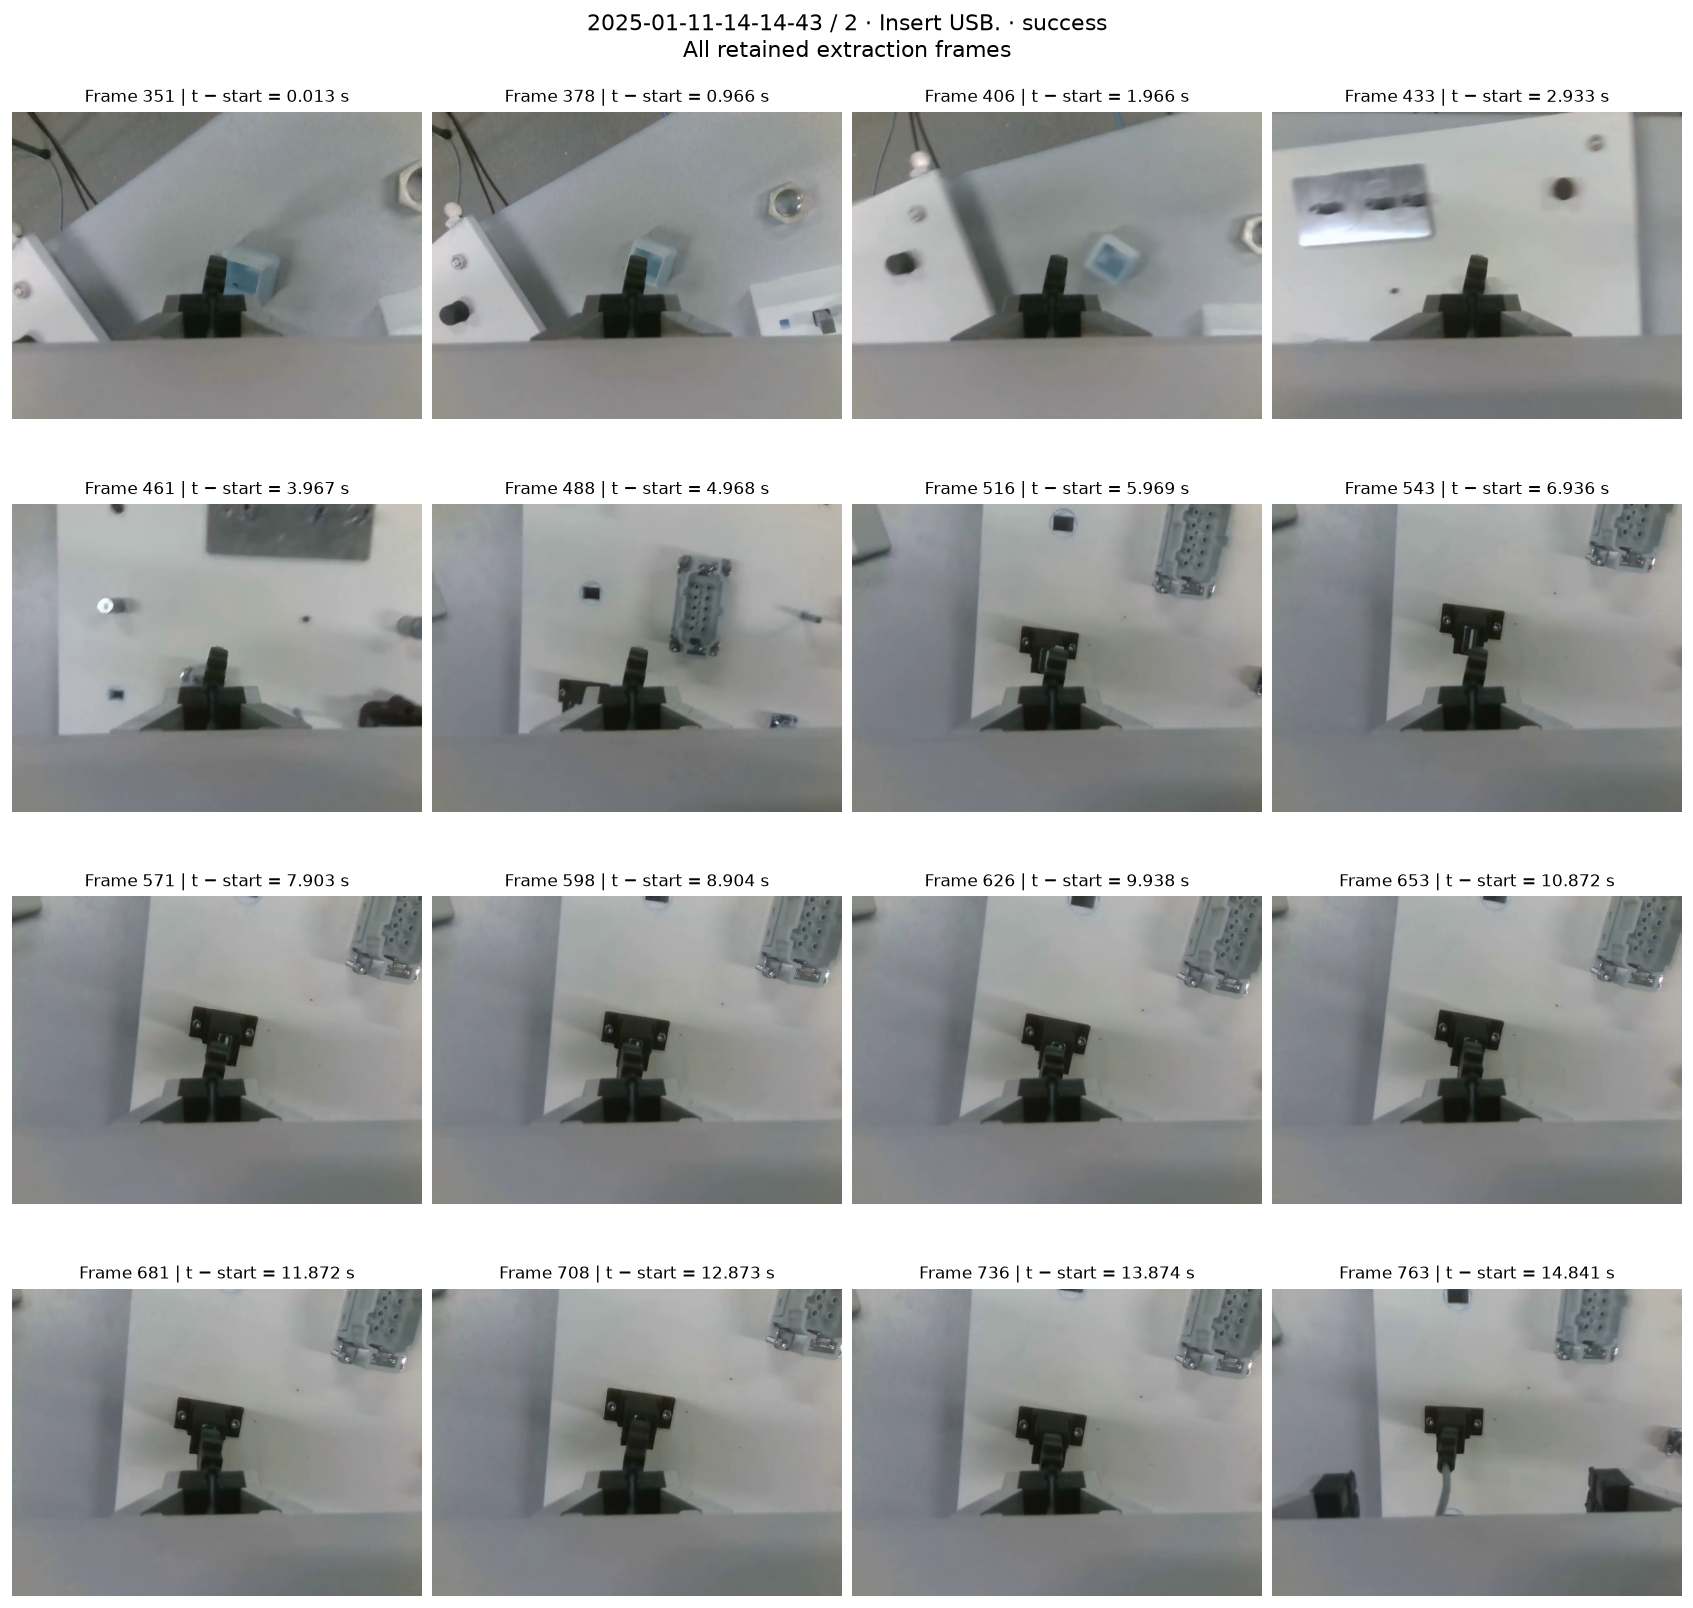

recording_frame_index,timestamp_unix_seconds,seconds_after_segment_start
351,1736601296.719157,0.012779
378,1736601297.672142,0.965764
406,1736601298.672457,1.966080
433,1736601299.638903,2.932525
461,1736601300.673041,3.966664
488,1736601301.674468,4.968090
516,1736601302.675494,5.969116
543,1736601303.642207,6.935829
571,1736601304.609226,7.902849
598,1736601305.609931,8.903553


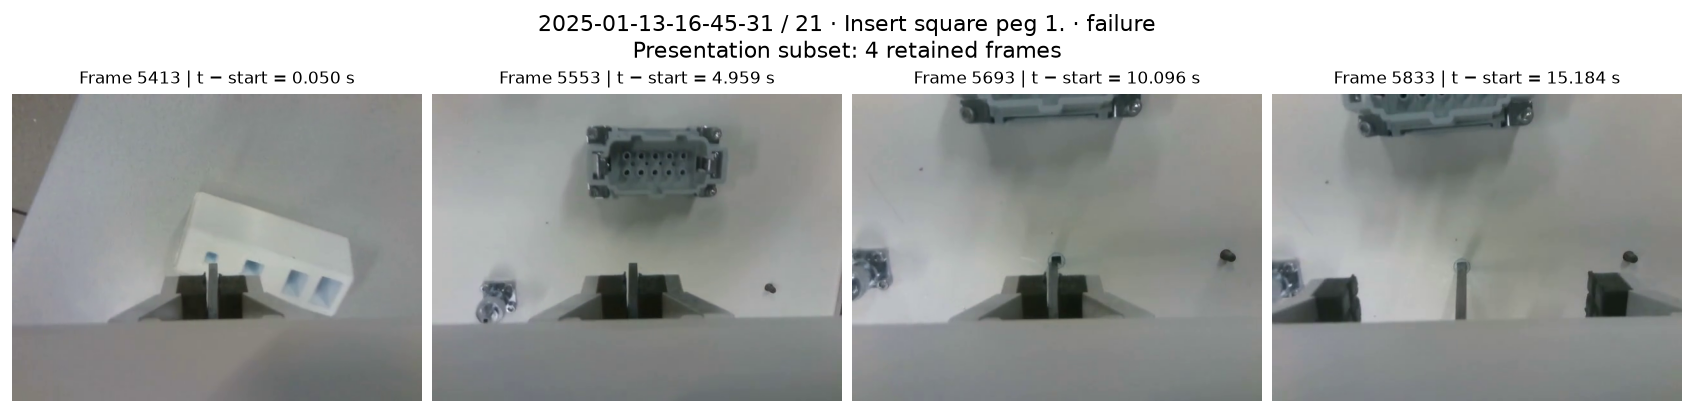

In [8]:
for i, sample in enumerate(examples):
    row = sample["row"]
    path = OUT/"figures"/(f"sample_{i+1}_contact_sheet.png")
    contact_sheet(sample, path, all_frames=(i==0))
    display(Image(filename=str(path)))
    times = pd.DataFrame({"recording_id":row.recording_id, "segment_id":row.segment_id,
        "recording_frame_index":sample["chosen"], "timestamp_unix_seconds":sample["vt"][sample["chosen"]],
        "seconds_after_segment_start":sample["vt"][sample["chosen"]]-row.start})
    times.to_csv(OUT/"tables"/f"sample_{i+1}_frame_times.csv", index=False)
    if i == 0:
        table(times[["recording_frame_index","timestamp_unix_seconds","seconds_after_segment_start"]])

**What you are seeing:** real hand-camera frames from the identified interval. The main sheet contains all extracted frames; the comparison sheet is a four-frame presentation subset of its own retained extraction frames.

**Why it matters:** the model summarizes several views of a **whole action**, not just its first or final image. Success/failure is taken from the annotation, not guessed from appearance. The two examples are not a controlled comparison of identical objects.

In [9]:
clips = []
for i, sample in enumerate(examples):
    display(Markdown(f"### Silent preview: `{sample['row'].recording_id} / {sample['row'].segment_id}`"))
    path = OUT/"media"/f"sample_{i+1}.webm"
    try:
        clip = export_clip(sample, path)
        clips.append(clip)
        display(Video(filename=str(path), embed=True, mimetype="video/webm", width=600))
        table(pd.DataFrame(clip.items(), columns=["preview property", "value"]))
    except RuntimeError as exc:
        warnings.append(str(exc))
        display(Markdown(f"> **Clip unavailable:** {exc}. Use the static contact sheet above."))

### Silent preview: `2025-01-11-14-14-43 / 2`

OpenCV: FFMPEG: tag 0x30385056/'VP80' is not supported with codec id 139 and format 'webm / WebM'


preview property,value
path,sample_1.webm
frames_decoded,89
fps,5.996360
encoded_fps,5.996000
duration_seconds,14.843229
source_start_trim_seconds,0.012779
last_output_timestamp_to_annotation_end_seconds,0.178329
playback_end_minus_annotation_end_seconds,-0.010669
maximum_hold_delay_seconds,0.081844
browser_playback_verified,False


### Silent preview: `2025-01-13-16-45-31 / 21`

OpenCV: FFMPEG: tag 0x30385056/'VP80' is not supported with codec id 139 and format 'webm / WebM'


preview property,value
path,sample_2.webm
frames_decoded,91
fps,5.991242
encoded_fps,5.991000
duration_seconds,15.189451
source_start_trim_seconds,0.049940
last_output_timestamp_to_annotation_end_seconds,0.161467
playback_end_minus_annotation_end_seconds,0.006068
maximum_hold_delay_seconds,0.104703
browser_playback_verified,False


**What you are seeing:** a smaller, silent presentation preview, sampled at a cadence derived from the median **source timestamp interval**, reduced to at most six frames per second. It holds the most recent source frame at each output time; the frame overlay shows that frame’s original index and time. Playback is approximately real-time, not a speed-up. The tables report the leading trim, the final output timestamp’s distance from the annotation end, encoded duration and maximum holding delay. The signed playback-end difference is positive if the last displayed frame is held slightly past the annotated end, and negative if playback ends slightly early (at most one preview step); no source frames outside the interval are included. Separate source timing and encoded playback timing are retained; exact output-to-source mappings are saved beside each clip as CSV.

**Why it matters:** container FPS alone does not prove physical synchronization. This timestamp-based preview is distinct from the 16 frames used for features. The exported file is decoded and counted with OpenCV. **Browser playback has not been verified**; the embedded contact sheets are the reliable static fallback.

<a id="sensors"></a>
## 4. What did the robot measure during the same interval?

These measurements are joined through **recording ID + segment ID**, then selected using the annotation’s start/end timestamps. No row-number-only join is used. The five streams have independent timestamp arrays. Below, three individual channels keep the figure readable; the full channel order is recorded in feature metadata.

Dots are actual observations, so the plot does not draw a continuous line across unobserved gaps. Gold lines mark the exact hand-camera timestamps of the retained frames. This verifies a shared timestamp interval, not an independently calibrated bound on camera/sensor hardware latency.

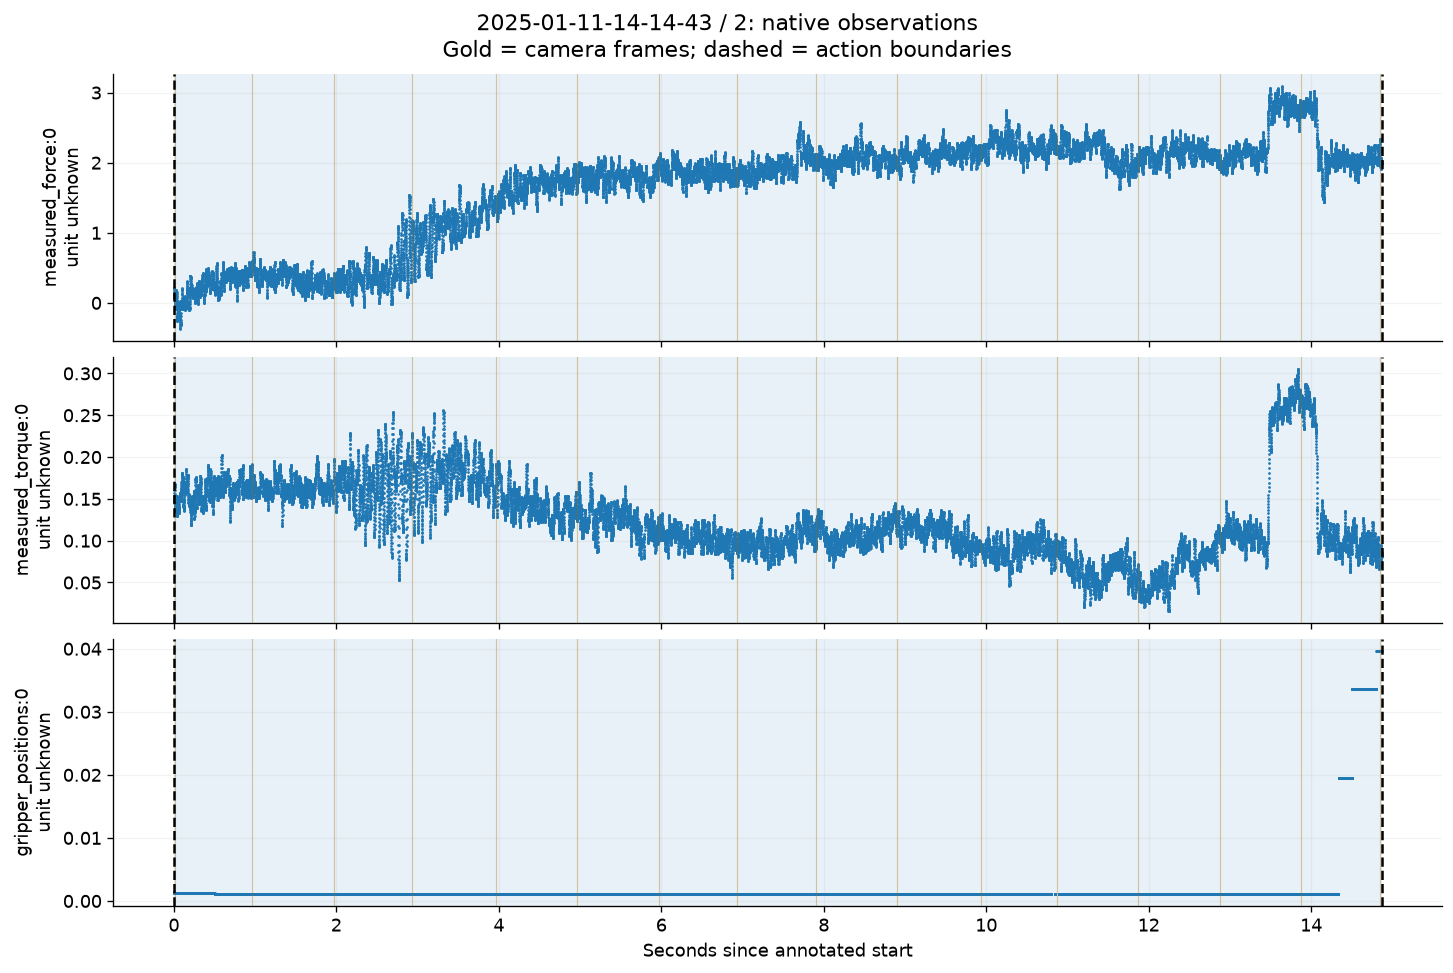

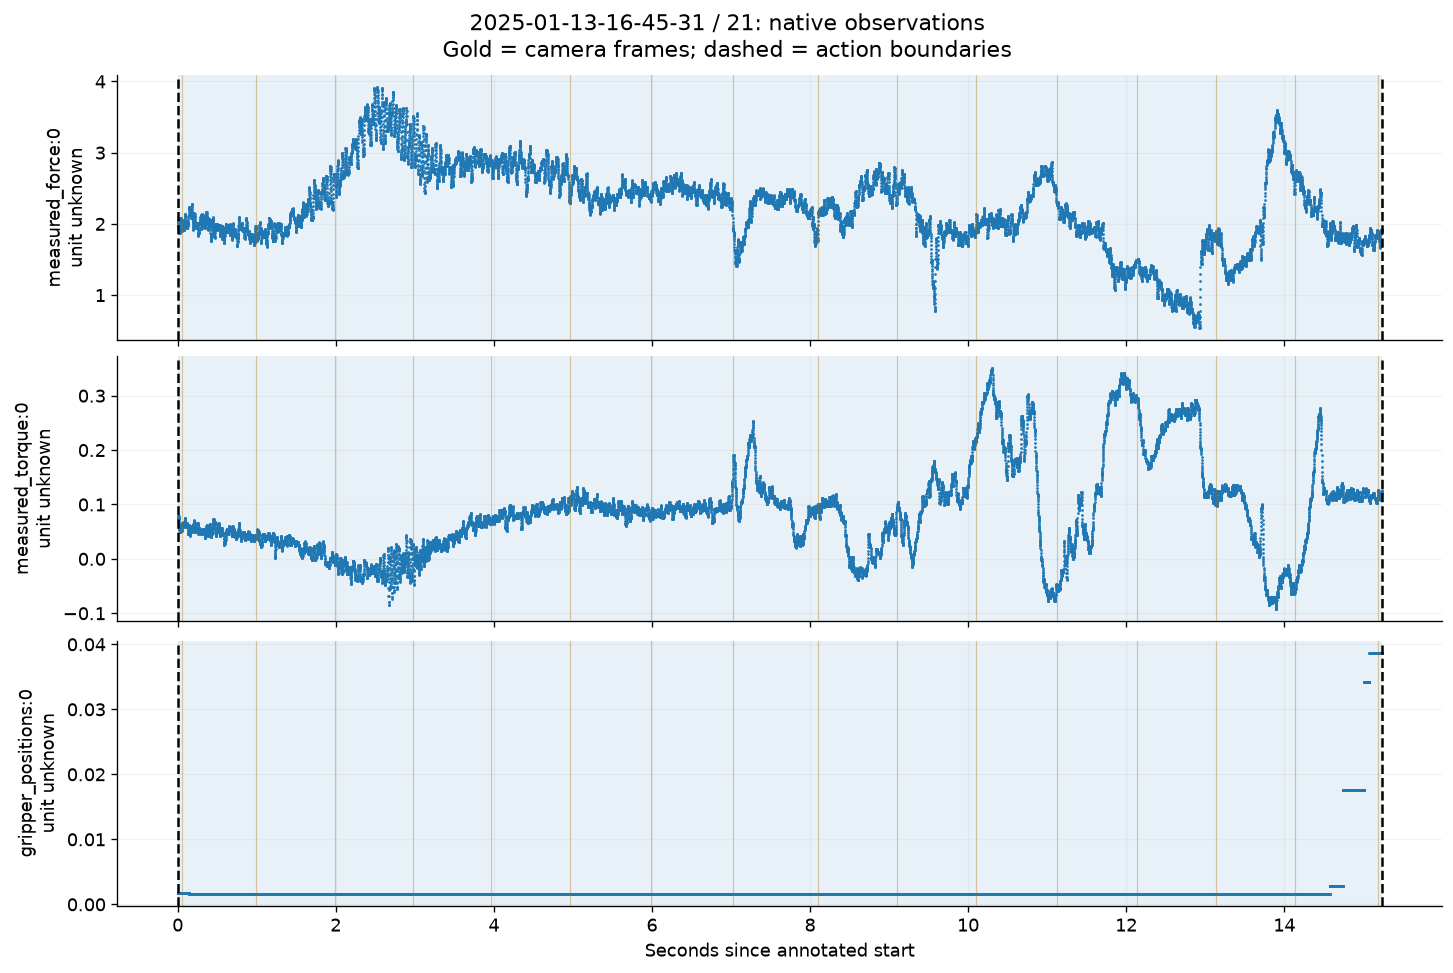

sample,stream,native_interval_shape,native_missing_values,gaps_over_5_recording_median_intervals,largest_gap_seconds
2025-01-11-14-14-43/2,measured_force,"(29735, 3)",0,48,0.006641
2025-01-11-14-14-43/2,measured_torque,"(29735, 3)",0,48,0.006641
2025-01-11-14-14-43/2,gripper_positions,"(14424, 2)",0,35,0.047547
2025-01-11-14-14-43/2,joint_efforts,"(14424, 7)",0,35,0.047547
2025-01-11-14-14-43/2,joint_velocities,"(14424, 7)",0,35,0.047547
2025-01-13-16-45-31/21,measured_force,"(15235, 3)",0,36,0.007398
2025-01-13-16-45-31/21,measured_torque,"(15235, 3)",0,36,0.007398
2025-01-13-16-45-31/21,gripper_positions,"(14783, 2)",0,28,0.007834
2025-01-13-16-45-31/21,joint_efforts,"(14783, 7)",0,28,0.007834
2025-01-13-16-45-31/21,joint_velocities,"(14783, 7)",0,28,0.007834


In [10]:
quality_rows = []
for i, sample in enumerate(examples):
    path = OUT/"figures"/f"sample_{i+1}_sensors.png"
    sensor_figure(sample, path)
    display(Image(filename=str(path)))
    for name, stream in sample["native"].items():
        gaps = np.diff(stream["t"])
        quality_rows.append({"sample":f"{sample['row'].recording_id}/{sample['row'].segment_id}",
            "stream":name, "native_interval_shape":str(stream['x'].shape),
            "native_missing_values":int((~np.isfinite(stream['x'])).sum()),
            "gaps_over_5_recording_median_intervals":int((gaps > 5*stream['native_dt']).sum()),
            "largest_gap_seconds":float(gaps.max())})
table(pd.DataFrame(quality_rows))

**What you are seeing:** native force, torque and gripper observations for the same samples shown in the images. Units are unknown in inspected metadata; numeric component `:0` is retained from the pipeline’s naming convention.

**Why it matters:** video and robot measurements describe the same action from different perspectives. Dense measurements are not extra labels, and gaps are not evidence of success or failure. The coverage masks used for cohort inclusion are saved audit decisions.

### From irregular time to normalized action progress

`alignment.resample_progress` linearly interpolates each stream to a fixed number of positions between start and end. Position 0 means start and position 1 means end; the seconds represented by one step depend on the action’s duration. It uses only in-interval finite observations, **never extrapolates**, and leaves large gaps as `NaN` (missing values). Its gap threshold is five times the recording-wide median native interval.

The helper calls this **existing function** on the selected recording’s five streams, one at a time, preserving that threshold. It compares the result and its statistics exactly with the corresponding saved arrays. This is a bounded two-sample reproduction, not feature-bank regeneration.

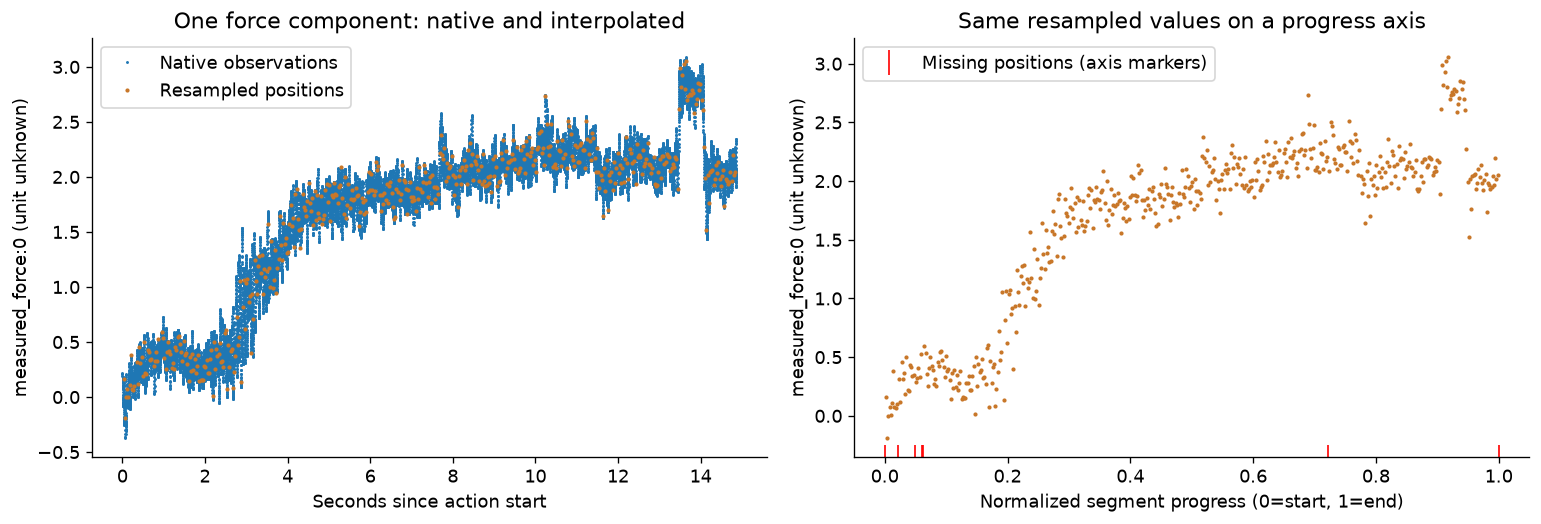

Resampled missing values across all channels: 250
Saved array parity: exact values including NaN locations for both examples.


In [11]:
if main:
    native = main["native"]["measured_force"]
    progress = np.linspace(0, 1, len(main["aligned"]))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].plot(native["t"]-main["row"].start, native["x"][:,0], '.', markersize=1.5)
    axes[0].plot(progress*main["row"].duration, main["aligned"][:,0], '.', markersize=3, color="#c87729")
    axes[0].set(title="One force component: native and interpolated", xlabel="Seconds since action start", ylabel="measured_force:0 (unit unknown)")
    axes[0].legend(["Native observations", "Resampled positions"])
    axes[1].plot(progress, main["aligned"][:,0], '.', color="#c87729", markersize=3)
    axes[1].set(title="Same resampled values on a progress axis", xlabel="Normalized segment progress (0=start, 1=end)", ylabel="measured_force:0 (unit unknown)")
    missing = ~np.isfinite(main["aligned"][:,0])
    axes[1].plot(progress[missing], np.zeros(missing.sum()), '|', transform=axes[1].get_xaxis_transform(), color="red", markersize=15, label="Missing positions (axis markers)")
    axes[1].legend()
    fig.tight_layout()
    show_figure(fig, "native_vs_resampled.png")
    print("Resampled missing values across all channels:", int((~np.isfinite(main["aligned"])).sum()))
    print("Saved array parity: exact values including NaN locations for both examples.")

**What you are seeing:** native observations and their interpolated values, followed by the same interpolated values on a 0–1 progress axis. Red baseline markers identify missing grid positions; they are not zero-valued sensor readings.

**Why it matters:** a fixed-length model input does not imply a fixed physical duration or fixed native sample rate. Statistics such as slope are computed against **normalized progress**, not per second. Missing values are preserved here; model-time imputation is a separate operation fitted on training data.

<a id="shapes"></a>
## 5. Shape ledger: raw observations → saved model inputs

We measure shapes from real arrays. The image processor is loaded **locally only**, without weights or inference, and applied to the actual retained frames. Its configuration checksum is compared with this run’s saved processor identity. A declared image size by itself would not establish an executed output shape.

The visual extraction implementation loads an RT-DETR checkpoint but executes **only the backbone**, spatially averages its maps, then averages across frames. It does not run the full detector or produce object detections in this pipeline. We reuse the saved visual vector; no backbone inference is run here.

In [12]:
pixel_values = None
processor_info = {}
if main:
    from transformers import RTDetrImageProcessor
    local_model = DATA/"cache/section1_models"/config["visual"]["revision"]
    processor_path = local_model/"preprocessor_config.json"
    if processor_path.exists():
        historical_model = json.loads((RUN/"pretrained_model.json").read_text())
        assert digest(processor_path) == historical_model["files"]["preprocessor_config.json"]["sha256"]
        track(processor_path, True)
        processor = RTDetrImageProcessor.from_pretrained(local_model, local_files_only=True)
        pixel_values = processor(images=list(main["images"]), return_tensors="pt")["pixel_values"]
        processor_info = {"executed_class":type(processor).__name__, "shape":list(pixel_values.shape),
            "dtype":str(pixel_values.dtype), "pixel_min":float(pixel_values.min()), "pixel_max":float(pixel_values.max()),
            "do_resize":processor.do_resize, "do_rescale":processor.do_rescale, "do_normalize":processor.do_normalize,
            "size": {"height": int(pixel_values.shape[-2]), "width": int(pixel_values.shape[-1])}}
        table(pd.DataFrame(processor_info.items(), columns=["actual processor observation", "value"]))
    else:
        warnings.append("Pixel preprocessing unavailable: local processor configuration missing")
        display(Markdown("> **Unavailable:** local processor configuration is missing; no download attempted."))

actual processor observation,value
executed_class,RTDetrImageProcessor
shape,"[16, 3, 640, 640]"
dtype,torch.float32
pixel_min,0.019608
pixel_max,1.000000
do_resize,True
do_rescale,True
do_normalize,False
size,"{'height': 640, 'width': 640}"


In [13]:
ledger = []
def measured(stage, array, meaning, source):
    ledger.append([stage, str(tuple(array.shape)), str(array.dtype), meaning, source, "Measured from a loaded array"])
if main:
    measured("One decoded RGB image", main["images"][0], "height pixels × width pixels × RGB colour channels", "OpenCV decode of hash-keyed hand.mp4; section1_features.extract")
    measured("Retained frame stack", main["images"], "frames × height × width × RGB channels", "features/<recording>.npz:frame_indices + decoded cache")
    if pixel_values is not None:
        measured("Executed pixel preprocessing", pixel_values, "frame processing batch × RGB channels × resized height × resized width", "local RTDetrImageProcessor.__call__; processor hash matches saved run")
    else:
        ledger.append(["Pixel preprocessing", "unknown", "unknown", "not executed", "local processor missing", "Unavailable/unverified"])
    for name, stream in main["native"].items():
        measured("Native interval: "+name, stream["x"], "native timestamped observations × components of this stream", "raw HDF5 robot_state/"+name)
    measured("Aligned sensor sequence", main["aligned"], "normalized action positions × ordered sensor channels", reference(resample_progress, ROOT))
    measured("Statistical sensor features", main["saved"]["statistics"], "ten statistics × channel count, flattened statistic-major", reference(statistics, ROOT))
    measured("Saved visual vector / visual loader input", main["saved"]["visual"], "pooled backbone feature components for one action sample", reference(load_features, ROOT))
    measured("Statistical branch loader input", main["saved"]["statistics"], "one action sample's flattened channel statistics", reference(evaluate_model, ROOT))
    measured("Separate PatchTST loader input", main["saved"]["sensor"], "positions × ordered sensor channels; not the statistics vector", reference(load_features, ROOT))
    educational_batch = main["saved"]["visual"][None, :]
    measured("Educational one-sample batch reshape", educational_batch, "1 action sample × visual components; NOT historical training batch size", "notebook: visual[None, :]")
    ledger.append(["Per-fit standardized model input", "same dimensions as branch loader input", "float32", "training-fitted mean/std and missing-value imputation; no fit executed here", reference(Standardizer, ROOT), "Inferred from inspected source/configuration"])
    ledger.append(["Historical training mini-batch setting", str(config["visual"]["batch_size"]), "not an array", "configured maximum action samples per update; last batch can be smaller", CONFIG_PATH+" visual.batch_size", "Verified from saved metadata"])
shape_table = pd.DataFrame(ledger, columns=["stage", "actual shape", "dtype", "meaning of each dimension", "source file/function", "evidence status"])
table(shape_table)
shape_table.to_csv(OUT/"tables/shape_ledger.csv", index=False)

stage,actual shape,dtype,meaning of each dimension,source file/function,evidence status
One decoded RGB image,"(480, 640, 3)",uint8,height pixels × width pixels × RGB colour channels,OpenCV decode of hash-keyed hand.mp4; section1_features.extract,Measured from a loaded array
Retained frame stack,"(16, 480, 640, 3)",uint8,frames × height × width × RGB channels,features/.npz:frame_indices + decoded cache,Measured from a loaded array
Executed pixel preprocessing,"(16, 3, 640, 640)",torch.float32,frame processing batch × RGB channels × resized height × resized width,local RTDetrImageProcessor.__call__; processor hash matches saved run,Measured from a loaded array
Native interval: measured_force,"(29735, 3)",float64,native timestamped observations × components of this stream,raw HDF5 robot_state/measured_force,Measured from a loaded array
Native interval: measured_torque,"(29735, 3)",float64,native timestamped observations × components of this stream,raw HDF5 robot_state/measured_torque,Measured from a loaded array
Native interval: gripper_positions,"(14424, 2)",float64,native timestamped observations × components of this stream,raw HDF5 robot_state/gripper_positions,Measured from a loaded array
Native interval: joint_efforts,"(14424, 7)",float64,native timestamped observations × components of this stream,raw HDF5 robot_state/joint_efforts,Measured from a loaded array
Native interval: joint_velocities,"(14424, 7)",float64,native timestamped observations × components of this stream,raw HDF5 robot_state/joint_velocities,Measured from a loaded array
Aligned sensor sequence,"(512, 22)",float32,normalized action positions × ordered sensor channels,src/reassemble/alignment.py:47 — resample_progress,Measured from a loaded array
Statistical sensor features,"(220,)",float32,"ten statistics × channel count, flattened statistic-major",src/reassemble/section1_features.py:32 — statistics,Measured from a loaded array


### The saved-feature boundary is the key idea

`section1_models.load_features` reads **previously extracted NPZ arrays**, checks their checksums, sorts by retained `row_index`, and restores cohort order. This notebook reads only the two required recording blocks and verifies each composite identity against the saved cohort before selecting its row. We do not load the entire training bank merely to show one sample.

| Branch | Input at saved-feature boundary | What the model subsequently does |
|---|---|---|
| Statistical sensor baseline | Per-channel mean, standard deviation, median, min, max, 25th/75th percentiles, range, RMS (root mean square), and progress slope | Training-only imputation/scaling, then logistic regression |
| Frozen visual baseline | Temporally pooled backbone vector | Training-only scaling, then learned 128-unit projection and binary classifier |
| Separate PatchTST comparison | Position-by-channel sensor sequence plus finite-value mask | Training-only per-channel scaling; missing values filled with training mean after scaling; temporal patch encoder and classifier |

Statistics are stored **statistic-major**: all channels’ means, then all channels’ standard deviations, and so on. The `channel_names` list below establishes component order. We never concatenate camera colour channels with sensor channels.

No direct raw-video-to-training DataLoader exists in this demonstrated path. Training consumes saved representations. The measured loader-boundary arrays are not newly fitted or standardized inputs: per-fit transforms are described from source. The educational `1 × features` reshape is not evidence of a historical batch size.

The complete start-to-end action is used in extraction. **This walkthrough does not demonstrate early warning or prediction before an action finishes.** Later prefix/boundary experiments are outside this chosen run.

In [14]:
if main:
    names = main["meta"]["channel_names"]
    table(pd.DataFrame({"channel position":np.arange(len(names)), "saved channel name":names,
                        "physical unit":"unknown in inspected metadata"}))
    stat_names = ["mean","std","median","min","max","q25","q75","range","RMS","progress slope"]
    width = len(names)
    table(pd.DataFrame({"statistic for "+names[0]:stat_names,
                        "actual saved value":main["saved"]["statistics"].reshape(len(stat_names),width)[:,0]}))

channel position,saved channel name,physical unit
0,measured_force:0,unknown in inspected metadata
1,measured_force:1,unknown in inspected metadata
2,measured_force:2,unknown in inspected metadata
3,measured_torque:0,unknown in inspected metadata
4,measured_torque:1,unknown in inspected metadata
5,measured_torque:2,unknown in inspected metadata
6,gripper_positions:0,unknown in inspected metadata
7,gripper_positions:1,unknown in inspected metadata
8,joint_efforts:0,unknown in inspected metadata
9,joint_efforts:1,unknown in inspected metadata


statistic for measured_force:0,actual saved value
mean,1.656469
std,0.731450
median,1.930582
min,-0.188962
max,3.053131
q25,1.332918
q75,2.128449
range,3.242093
RMS,1.810776
progress slope,2.153209


<a id="trace"></a>
## 6. Trace this sample back to the code

Use this table to navigate during questions. Line numbers are obtained from the **current checked-out functions**. The run’s preserved configuration identifies the historical bank; current source is not silently treated as the original Git revision. Exact two-sample sensor/statistics parity and retained-frame equality are tested; historical backbone inference is not reproduced.

In [15]:
from reassemble import inventory, audit_report, media
trace = pd.DataFrame([
    ["Where is a sample selected?", reference(cohort, ROOT)+"; notebook selection cell", "saved audit cohort + fixed action/outcome + duration median", "composite recording/segment ID and cohort row"],
    ["Where do boundaries and labels originate?", reference(inventory.audit_recording, ROOT)+"; inventory.scalar", "HDF5 segments_info/<id>: start, end, text, success", "action_from_text; failure=int(not success)"],
    ["Where are exclusions defined?", reference(audit_report.main, ROOT), "saved sensor/video usability plus documented issues", "primary_task & dual_complete"],
    ["Where are images read?", reference(extract, ROOT)+"; "+reference(media.inspect_video, ROOT), "raw hand blob → existing hash-keyed MP4 + timestamps/hand", "decoded RGB frames at retained recording-relative indices"],
    ["Where are measurements read?", reference(extract, ROOT), "HDF5 robot_state/<stream>, timestamps/<stream>", "five native numeric streams"],
    ["Where is alignment performed?", reference(resample_progress, ROOT), "stream timestamps, values and sample start/end", "progress sequence with gaps retained as NaN"],
    ["Where are features computed/saved?", reference(extract, ROOT)+"; "+reference(statistics, ROOT), "decoded frames + aligned sensor sequence", "features/<recording>.npz and channel/checksum JSON"],
    ["Where do modelling branches load them?", reference(load_features, ROOT)+"; "+reference(evaluate_model, ROOT), "NPZ row_index + visual/sensor/statistics", "cohort-ordered arrays; branch chosen by model kind"]],
    columns=["question", "actual file/function", "input", "output"])
table(trace)
trace.to_csv(OUT/"tables/code_trace.csv", index=False)
for sample in examples:
    r = sample["row"]
    print(f"{r.recording_id}/{r.segment_id} → cohort row {r.name} → {sample['bank'].name} slot {sample['slot']}")

question,actual file/function,input,output
Where is a sample selected?,src/reassemble/section1_features.py:24 — cohort; notebook selection cell,saved audit cohort + fixed action/outcome + duration median,composite recording/segment ID and cohort row
Where do boundaries and labels originate?,src/reassemble/inventory.py:27 — audit_recording; inventory.scalar,"HDF5 segments_info/: start, end, text, success",action_from_text; failure=int(not success)
Where are exclusions defined?,src/reassemble/audit_report.py:39 — main,saved sensor/video usability plus documented issues,primary_task & dual_complete
Where are images read?,src/reassemble/section1_features.py:60 — extract; src/reassemble/media.py:26 — inspect_video,raw hand blob → existing hash-keyed MP4 + timestamps/hand,decoded RGB frames at retained recording-relative indices
Where are measurements read?,src/reassemble/section1_features.py:60 — extract,"HDF5 robot_state/, timestamps/",five native numeric streams
Where is alignment performed?,src/reassemble/alignment.py:47 — resample_progress,"stream timestamps, values and sample start/end",progress sequence with gaps retained as NaN
Where are features computed/saved?,src/reassemble/section1_features.py:60 — extract; src/reassemble/section1_features.py:32 — statistics,decoded frames + aligned sensor sequence,features/.npz and channel/checksum JSON
Where do modelling branches load them?,src/reassemble/section1_models.py:123 — load_features; src/reassemble/section1_models.py:134 — evaluate_model,NPZ row_index + visual/sensor/statistics,cohort-ordered arrays; branch chosen by model kind


2025-01-11-14-14-43/2 → cohort row 2106 → 2025-01-11-14-14-43.npz slot 1
2025-01-13-16-45-31/21 → cohort row 3326 → 2025-01-13-16-45-31.npz slot 20


### Three short pieces of the actual implementation

The first excerpt shows selection at the saved cohort boundary. The second shows the ten statistical summaries being flattened. The third shows modelling loading saved arrays and restoring cohort order. These are displayed for explanation, not executed as training code.

In [16]:
for function, limit in [(cohort, 7), (statistics, 11), (load_features, 12)]:
    lines, start = inspect.getsourcelines(function)
    excerpt = "\n".join(f"{start+i:4d}  {line.rstrip()}" for i,line in enumerate(lines[:limit]))
    display(Markdown("**"+reference(function,ROOT)+"**\n\n```python\n"+excerpt+"\n```"))

**src/reassemble/section1_features.py:24 — cohort**

```python
  24  def cohort(config):
  25      f=pd.read_parquet(Path(config['audit_run'])/'tables_v2/cohort.parquet')
  26      f=f.loc[f.primary_task & f.dual_complete].copy().reset_index(drop=True)
  27      assert len(f)==4530 and f.failure.sum()==509 and f.recording_id.nunique()==148
  28      assert not f.duplicated(['recording_id','segment_id']).any()
  29      return f
```

**src/reassemble/section1_features.py:32 — statistics**

```python
  32  def statistics(x):
  33      """Per-segment channel statistics; no fitted population quantities."""
  34      q=np.nanquantile(x,[.25,.5,.75],axis=0)
  35      lo,hi=np.nanmin(x,axis=0),np.nanmax(x,axis=0)
  36      t=np.linspace(0,1,len(x))[:,None];valid=np.isfinite(x)
  37      n=valid.sum(0);tx=np.where(valid,t,0).sum(0)/np.maximum(n,1)
  38      xm=np.nanmean(x,axis=0);tc=t-tx
  39      slope=np.nansum(tc*(x-xm),0)/np.maximum(np.where(valid,tc**2,0).sum(0),1e-12)
  40      return np.concatenate([xm,np.nanstd(x,axis=0),q[1],lo,hi,q[0],q[2],hi-lo,np.sqrt(np.nanmean(x*x,0)),slope]).astype('float32')
```

**src/reassemble/section1_models.py:123 — load_features**

```python
 123  def load_features(config):
 124      f=cohort(config);run=Path(config['run_dir']);blocks=[]
 125      for p in sorted((run/'features').glob('*.npz')):
 126          assert sha(p)==json.loads(p.with_suffix('.json').read_text())['feature_sha256']
 127          with np.load(p) as z:blocks.append({k:z[k] for k in ['row_index','visual','sensor','statistics']})
 128      ix=np.concatenate([b['row_index'] for b in blocks]);assert sorted(ix)==list(range(len(f)))
 129      order=np.argsort(ix);arrays={k:np.concatenate([b[k] for b in blocks])[order] for k in ['visual','sensor','statistics']}
 130      arrays['action']=np.stack([(f.action==a).to_numpy(dtype='float32') for a in ['pick','insert','remove','place']],axis=1)
 131      return f,arrays
```

<a id="verification"></a>
## Verification and limits

The checks below concern data lineage and this teaching artifact. They are not a new scientific audit, benchmark or evaluation. Raw data are opened read-only; no existing research outputs are regenerated. Source identities use inexpensive hashes for small code/config/table/feature files and filesystem metadata plus retained hashes for raw recordings. We do not hash the entire raw dataset.

**Known limits:** physical sensor units were not established; audio synchronization is unverified and audio is excluded; neither full-detector inference nor visual feature regeneration is performed; per-fit model normalization is explained from code rather than re-fitted; browser playback is not tested. Example selection uses labels to illustrate both outcomes, not to claim predictive performance. Both examples may differ in object and recording conditions.

In [17]:
for p in [ROOT/"src/reassemble"/name for name in
          ("alignment.py","inventory.py","media.py","audit_report.py","section1_features.py","section1_models.py")]:
    track(p, True)
if (DATA/"downloads/README.txt").exists():
    track(DATA/"downloads/README.txt", True)
raw_after = {p.name: [p.stat().st_size, p.stat().st_mtime_ns] for p in raw_files}
checks["all_listed_raw_metadata_unchanged"] = raw_before == raw_after
checks["read_inputs_metadata_unchanged"] = all(
    identity(ROOT/item["path"], ROOT)[key] == item[key]
    for item in inputs.values() for key in ("bytes","mtime_ns"))
checks["retained_frames_decoded_and_match_current_selection"] = bool(examples)
checks["local_processor_executed_without_weights"] = pixel_values is not None
checks["clips_fully_decoded"] = len(clips) == len(examples) and bool(examples)
checks["browser_playback_verified"] = False
assert checks["all_listed_raw_metadata_unchanged"] and checks["read_inputs_metadata_unchanged"]
warnings.extend(["Sensor physical units unavailable in inspected metadata",
                 "Audio annotation-clock alignment unverified; excluded from demonstrated pipeline",
                 "Browser playback not verified; static contact sheets embedded",
                 "Historical visual inference and fitted model normalization not rerun"])
verification = {"checks":checks, "warnings":warnings, "selected_samples":selection_details,
                "processor":processor_info, "clips":clips, "shape_ledger":shape_table.to_dict("records")}
(OUT/"reports/verification.json").write_text(json.dumps(verification, indent=2))
(OUT/"reports/warnings.json").write_text(json.dumps(warnings, indent=2))
(OUT/"manifests/inputs.json").write_text(json.dumps(list(inputs.values()), indent=2))
(OUT/"reports/summary.txt").write_text(
    "Read-only REASSEMBLE Section 1 teaching walkthrough.\n"
    + "Samples: " + ", ".join(f"{x['recording_id']}/{x['segment_id']}" for x in selection_details)
    + "\nNo training, evaluation, downloads or feature-bank regeneration.\n"
    + "Browser playback unverified. Open 01_reassemble_eda.html.\n")
table(pd.DataFrame(checks.items(), columns=["check", "result"]))
display(Markdown("The fresh-kernel runner exports the embedded offline HTML and records software/Git provenance and an output manifest. The input checks above cover the raw recordings and read artifacts."))

check,result
saved_cohort_identity_and_order_match,True
sample_raw_annotations_feature_rows_and_timestamps,True
single_sample_sensor_and_statistics_exact_saved_parity,True
all_listed_raw_metadata_unchanged,True
read_inputs_metadata_unchanged,True
retained_frames_decoded_and_match_current_selection,True
local_processor_executed_without_weights,True
clips_fully_decoded,True
browser_playback_verified,False


The fresh-kernel runner exports the embedded offline HTML and records software/Git provenance and an output manifest. The input checks above cover the raw recordings and read artifacts.

<details><summary><strong>Appendix: precise evidence boundaries and rerun notes</strong></summary>

- The existing `cohort` reader contains historical count assertions. A changed cohort should fail loudly rather than silently become a different study.
- Raw-file size and mtime are checked against saved inventory entries; saved raw SHA256 identities link caches and feature metadata. Raw payload hashes are **not** recomputed.
- Only the selected two HDF5 recordings’ five sensor streams are loaded, one stream at a time. No event arrays or audio payloads are decoded. Camera metadata and sparse hand frames are read from the existing encoded cache; previews are bounded to 240 frames per example.
- `load_features` normally concatenates all recording banks. This notebook mirrors its single-block row mapping to avoid loading that complete bank. It checks the original bank checksum, full saved cohort order, and exact composite IDs.
- Exact sensor/statistical equality establishes current two-sample parity, not whole-bank historical reproduction. The original historical extraction signature is retained in each feature JSON; source snapshots are separately fingerprinted in the input manifest.
- The HDF5 reader may expose encoded blobs as opaque scalars or integer byte arrays. These are not image or waveform tensor shapes. Actual decoding is necessary before claiming pixel dimensions.
- The PNG contact sheets and sensor plots are embedded in notebook outputs and HTML. WebM clips are embedded as data URIs. The HTML needs no remote JavaScript, CDN or relative media assets; separate media/figure files are retained for inspection.
- The notebook intentionally performs no predictive inference. Annotated labels are not model predictions. A successful shape/read check does not prove predictive validity.
- To execute in another fresh kernel and produce a new HTML bundle: run `ma_thesis_env/bin/python -B tutorials/EDA/run_eda.py 01_reassemble_eda.ipynb` from the repository root. Do not execute into an old output folder. See the adjacent README for manual selection.

</details>